# Experiment 2: PILOT V02 and Three Comparators
Four methods: **PILOT V02 (Oct29)**, **PILOT Original (Oct21)**, **UniFP Original**, and **Pos**. Selection uses recorded checkpoint identities, not evaluation directory names. No FiLM oscillation analysis, simulation, training, or modified-policy evaluation.

In [1]:
import os, json, sys, importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebooks/pilot_v02_comparison.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
import pilot_v02_comparison as cohort
cohort = importlib.reload(cohort)
CONFIG = cohort.defaults(ROOT)
# Edit roots/output or individual method run_name/checkpoint_sha256 selectors here.
# Both PILOT entries intentionally have native task b1z1_pact, but distinct IDs.
CONFIG["methods"]


{'unifp': {'task': 'b1z1_unifp_original',
  'display_name': 'UniFP',
  'run_name': 'Oct23_15-25-20_upstream_architecture'},
 'pos': {'task': 'b1z1_ppo_pos',
  'display_name': 'Pos',
  'run_name': 'Oct23_16-58-40_position_only'},
 'pilot_original': {'task': 'b1z1_pact',
  'display_name': 'PILOT (Original)',
  'run_name': 'Oct21_00-46-21_b1z1_pact_improved',
  'film_v02': False},
 'pilot_v02': {'task': 'b1z1_pact',
  'display_name': 'PILOT V02',
  'run_name': 'Oct29_15-14-37_b1z1_pact_improved',
  'film_v02': True}}

In [2]:
CONFIG.update({
    "load_range": "in",  # Exp1: analyze OOD separately.
    "motion": "combined",  # Also export the existing separate motion-mode table.
    "loading": ["loaded", "unloaded"],  # Exp2: never pool these conditions.
    "comparison_loading": "loaded",
    "acceleration_metrics": True,
    "rmse_bootstrap_resamples": 10000,
    "rmse_confidence_level": 0.95,
    "rmse_resampling_seed": 0,
    "reuse_summaries": True,
    # Times New Roman when installed; all sizes in points.
    "figure_title_font_size": 12, "title_font_size": 11,
    "axis_label_font_size": 10, "tick_font_size": 9,
    "legend_font_size": 9, "annotation_font_size": 8,
})
# Optional JSON file for unattended execution; does not modify old notebooks.
if os.environ.get("PILOT_COMPARISON_CONFIG"):
    CONFIG.update(json.loads(Path(os.environ["PILOT_COMPARISON_CONFIG"]).read_text()))
methods, recordings, inventory = cohort.resolve_cohorts(CONFIG, 2)
display(pd.DataFrame(inventory))


,method,task,checkpoint_sha256,recordings,evaluation_seeds,training_seeds,status
0,unifp,b1z1_unifp_original,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,9,"[0, 1, 2]",[],available
1,pos,b1z1_ppo_pos,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,9,"[0, 1, 2]",[],available
2,pilot_original,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,9,"[0, 1, 2]",[],available
3,pilot_v02,b1z1_pact,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,9,"[0, 1, 2]",[],available


## Native Metrics and Exports
Run the existing summarizer separately for each checkpoint. Errors use finite pre-failure samples; S_track includes zero-credit failed tails. Physical limits pool valid joint-substep counts within each seed. Existing units, recovery windows/dwell, histogram frames, and equal-seed aggregation remain unchanged. All outputs go to `analysis/pilot_v02_comparison`, never the old analysis folders.

In [3]:
summaries, inventory, confidence = cohort.summarize_tasks(CONFIG, 2)
for method, summary in summaries.items():
    print(summary["display_name"])
    display(pd.DataFrame(summary["aggregates"]))
    print("\n".join(summary["diagnostics"]) or "No coverage diagnostics.")


Exp2: UniFP (9 recordings)
Exp2: Pos (9 recordings)
Exp2: PILOT (Original) (9 recordings)
Exp2: PILOT V02 (9 recordings)
UniFP


,profile,loading,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,pushing,loaded,ee_error_m,m,0.037348,0.000025,3,150,150.0
1,pushing,loaded,planar_velocity_error_m_s,m/s,0.050652,0.000188,3,150,150.0
2,pushing,loaded,yaw_error_rad_s,rad/s,0.108994,0.000315,3,150,150.0
3,pushing,loaded,S_track,fraction,0.925995,0.000756,3,150,150.0
4,pushing,loaded,failure_rate,fraction,0.000000,0.000000,3,150,150.0
5,pushing,loaded,S_track_velocity,fraction,0.954033,0.000642,3,150,150.0
6,pushing,loaded,S_track_manipulation,fraction,0.966681,0.000257,3,150,150.0
7,pushing,loaded,torso_angular_acceleration_rms,rad/s^2,12.152603,0.008394,3,150,150.0
8,pushing,loaded,ee_linear_acceleration_rms,m/s^2,6.698624,0.010147,3,150,150.0
9,pushing,loaded,actuator_saturation_pct,%,0.021848,0.000339,3,150,NaN


pushing/unloaded: evaluation seeds []; expected [0, 1, 2]
pulling/unloaded: evaluation seeds []; expected [0, 1, 2]
carrying/unloaded: evaluation seeds []; expected [0, 1, 2]
Pos


,profile,loading,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,pushing,loaded,ee_error_m,m,0.050604,0.000025,3,150,150.0
1,pushing,loaded,planar_velocity_error_m_s,m/s,0.070384,0.000132,3,150,150.0
2,pushing,loaded,yaw_error_rad_s,rad/s,0.074120,0.000328,3,150,150.0
3,pushing,loaded,S_track,fraction,0.891310,0.002570,3,150,150.0
4,pushing,loaded,failure_rate,fraction,0.000000,0.000000,3,150,150.0
5,pushing,loaded,S_track_velocity,fraction,0.992419,0.000326,3,150,150.0
6,pushing,loaded,S_track_manipulation,fraction,0.897214,0.002797,3,150,150.0
7,pushing,loaded,torso_angular_acceleration_rms,rad/s^2,11.125204,0.017936,3,150,150.0
8,pushing,loaded,ee_linear_acceleration_rms,m/s^2,7.280943,0.011897,3,150,150.0
9,pushing,loaded,actuator_saturation_pct,%,0.000000,0.000000,3,150,NaN


pushing/unloaded: evaluation seeds []; expected [0, 1, 2]
pulling/unloaded: evaluation seeds []; expected [0, 1, 2]
carrying/unloaded: evaluation seeds []; expected [0, 1, 2]
PILOT (Original)


,profile,loading,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,pushing,loaded,ee_error_m,m,0.038828,0.000076,3,150,150.0
1,pushing,loaded,planar_velocity_error_m_s,m/s,0.057250,0.000092,3,150,150.0
2,pushing,loaded,yaw_error_rad_s,rad/s,0.068331,0.000597,3,150,150.0
3,pushing,loaded,S_track,fraction,0.970481,0.000354,3,150,150.0
4,pushing,loaded,failure_rate,fraction,0.000000,0.000000,3,150,150.0
5,pushing,loaded,S_track_velocity,fraction,0.989114,0.000718,3,150,150.0
6,pushing,loaded,S_track_manipulation,fraction,0.980210,0.000331,3,150,150.0
7,pushing,loaded,torso_angular_acceleration_rms,rad/s^2,10.850089,0.014486,3,150,150.0
8,pushing,loaded,ee_linear_acceleration_rms,m/s^2,12.224469,0.022423,3,150,150.0
9,pushing,loaded,actuator_saturation_pct,%,0.000000,0.000000,3,150,NaN


pushing/unloaded: evaluation seeds []; expected [0, 1, 2]
pulling/unloaded: evaluation seeds []; expected [0, 1, 2]
carrying/unloaded: evaluation seeds []; expected [0, 1, 2]
PILOT V02


,profile,loading,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,pushing,loaded,ee_error_m,m,0.027065,0.000196,3,150,150.0
1,pushing,loaded,planar_velocity_error_m_s,m/s,0.042312,0.000043,3,150,150.0
2,pushing,loaded,yaw_error_rad_s,rad/s,0.062141,0.000202,3,150,150.0
3,pushing,loaded,S_track,fraction,0.989424,0.001718,3,150,150.0
4,pushing,loaded,failure_rate,fraction,0.000000,0.000000,3,150,150.0
5,pushing,loaded,S_track_velocity,fraction,0.998733,0.000369,3,150,150.0
6,pushing,loaded,S_track_manipulation,fraction,0.990519,0.001485,3,150,150.0
7,pushing,loaded,torso_angular_acceleration_rms,rad/s^2,8.329900,0.038253,3,150,150.0
8,pushing,loaded,ee_linear_acceleration_rms,m/s^2,12.306375,0.015797,3,150,150.0
9,pushing,loaded,actuator_saturation_pct,%,0.000169,0.000065,3,150,NaN


pushing/unloaded: evaluation seeds []; expected [0, 1, 2]
pulling/unloaded: evaluation seeds []; expected [0, 1, 2]
carrying/unloaded: evaluation seeds []; expected [0, 1, 2]


## Existing Comparison Tables and Figures
All four methods appear in the main and focused tables and figures. Protocol and seed-coverage checks are unchanged. CSV/LaTeX and PDF/PNG exports are retained.

main


pushing                                  \
                       EE [m] ↓ Velocity [m/s] ↓  Yaw [rad/s] ↓   
Method                                                            
UniFP             0.037 ± 0.000    0.051 ± 0.000  0.109 ± 0.000   
Pos               0.051 ± 0.000    0.070 ± 0.000  0.074 ± 0.000   
PILOT (Original)  0.039 ± 0.000    0.057 ± 0.000  0.068 ± 0.001   
PILOT V02         0.027 ± 0.000    0.042 ± 0.000  0.062 ± 0.000   

                                                 \
                  Tracking [%] ↑  Failure [%] ↓   
Method                                            
UniFP             92.600 ± 0.076  0.000 ± 0.000   
Pos               89.131 ± 0.257  0.000 ± 0.000   
PILOT (Original)  97.048 ± 0.035  0.000 ± 0.000   
PILOT V02         98.942 ± 0.172  0.000 ± 0.000   

                                                             \
                 torso_angular_acceleration_rms [rad/s^2] ↓   
Method                                                        
UniFP                                        12.153 ± 0.008   
Pos                                          11.125 ± 0.018   
PILOT (Original)                             10.850 ± 0.014   
PILOT V02                                     8.330 ± 0.038   

                                                             pulling  \
                 ee_linear_acceleration_rms [m/s^2] ↓       EE [m] ↓   
Method                                                                 
UniFP                                   6.699 ± 0.010  0.043 ± 0.000   
Pos                                     7.281 ± 0.012  0.057 ± 0.000   
PILOT (Original)                       12.224 ± 0.022  0.048 ± 0.000   
PILOT V02                              12.306 ± 0.016  0.035 ± 0.000   

                                                  ...                 \
                 Velocity [m/s] ↓  Yaw [rad/s] ↓  ...  Failure [%] ↓   
Method                                            ...                  
UniFP               0.051 ± 0.000  0.068 ± 0.000  ...  0.000 ± 0.000   
Pos                 0.062 ± 0.000  0.109 ± 0.000  ...  0.000 ± 0.000   
PILOT (Original)    0.095 ± 0.000  0.068 ± 0.000  ...  0.000 ± 0.000   
PILOT V02           0.056 ± 0.000  0.061 ± 0.000  ...  0.000 ± 0.000   

                                                             \
                 torso_angular_acceleration_rms [rad/s^2] ↓   
Method                                                        
UniFP                                        11.351 ± 0.018   
Pos                                          12.875 ± 0.019   
PILOT (Original)                              9.313 ± 0.013   
PILOT V02                                     7.342 ± 0.017   

                                                            carrying  \
                 ee_linear_acceleration_rms [m/s^2] ↓       EE [m] ↓   
Method                                                                 
UniFP                                   6.578 ± 0.007  0.045 ± 0.000   
Pos                                     9.969 ± 0.013  0.057 ± 0.000   
PILOT (Original)                       12.665 ± 0.007  0.034 ± 0.000   
PILOT V02                              11.482 ± 0.020  0.039 ± 0.000   

                                                                  \
                 Velocity [m/s] ↓  Yaw [rad/s] ↓  Tracking [%] ↑   
Method                                                             
UniFP               0.044 ± 0.000  0.065 ± 0.000  87.492 ± 0.082   
Pos                 0.068 ± 0.000  0.084 ± 0.001  82.826 ± 0.100   
PILOT (Original)    0.063 ± 0.000  0.090 ± 0.001  96.869 ± 0.055   
PILOT V02           0.040 ± 0.000  0.061 ± 0.001  98.204 ± 0.097   

                                                                            \
                  Failure [%] ↓ torso_angular_acceleration_rms [rad/s^2] ↓   
Method                                                                       
UniFP             0.000 ± 0.000                             12.106 ± 0.030   
Pos     

physical_limits


Saturation [%] ↓ Position [%] ↓ Velocity [%] ↓
Method           Profile                                                
UniFP            pushing     0.022 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 pulling     0.002 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 carrying    0.023 ± 0.000  0.020 ± 0.001  0.000 ± 0.000
Pos              pushing     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 carrying    0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
PILOT (Original) pushing     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 carrying    0.000 ± 0.000  0.417 ± 0.004  0.000 ± 0.000
PILOT V02        pushing     0.000 ± 0.000  0.008 ± 0.002  0.000 ± 0.000
                 pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
                 carrying    0.000 ± 0.000  0.195 ± 0.012  0.000 ± 0.000

response


Peak EE [m] ↓ Recovery [s] ↓  Recovered [%] ↑  \
Method           Profile                                                   
UniFP            pushing   0.114 ± 0.001  0.455 ± 0.014   97.833 ± 0.577   
                 pulling   0.104 ± 0.000  0.267 ± 0.002  100.000 ± 0.000   
                 carrying  0.160 ± 0.001  0.291 ± 0.006   75.000 ± 0.000   
Pos              pushing   0.099 ± 0.000  0.137 ± 0.005   98.500 ± 1.323   
                 pulling   0.099 ± 0.000  0.274 ± 0.030   94.500 ± 1.323   
                 carrying  0.113 ± 0.000  0.083 ± 0.012   75.000 ± 0.000   
PILOT (Original) pushing   0.103 ± 0.000  0.177 ± 0.005  100.000 ± 0.000   
                 pulling   0.088 ± 0.000  0.202 ± 0.024   83.833 ± 1.258   
                 carrying  0.104 ± 0.001  0.218 ± 0.016   99.500 ± 0.500   
PILOT V02        pushing   0.073 ± 0.001  0.081 ± 0.003  100.000 ± 0.000   
                 pulling   0.072 ± 0.001  0.069 ± 0.002  100.000 ± 0.000   
                 carrying  0.099 ± 0.000  0.190 ± 0.007  100.000 ± 0.000   

                          EE recovered [%] ↑ Velocity recovered [%] ↑  
Method           Profile                                               
UniFP            pushing     100.000 ± 0.000           98.333 ± 0.289  
                 pulling     100.000 ± 0.000          100.000 ± 0.000  
                 carrying     75.000 ± 0.000          100.000 ± 0.000  
Pos              pushing      99.000 ± 0.866          100.000 ± 0.000  
                 pulling     100.000 ± 0.000           98.667 ± 0.289  
                 carrying     75.000 ± 0.000          100.000 ± 0.000  
PILOT (Original) pushing     100.000 ± 0.000          100.000 ± 0.000  
                 pulling      99.167 ± 0.764           88.167 ± 1.155  
                 carrying    100.000 ± 0.000          100.000 ± 0.000  
PILOT V02        pushing     100.000 ± 0.000          100.000 ± 0.000  
                 pulling     100.000 ± 0.000          100.000 ± 0.000  
                 carrying    100.000 ± 0.000          100.000 ± 0.000

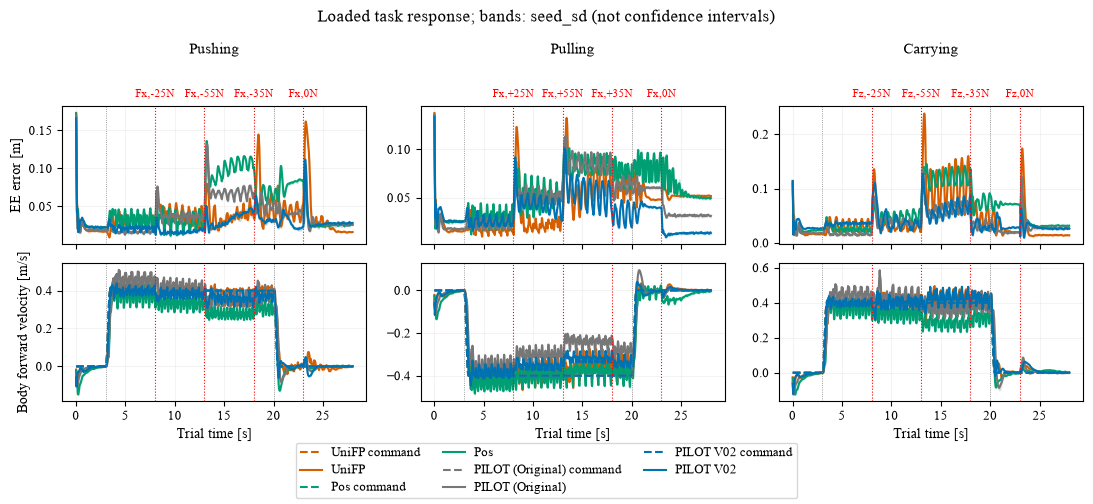

UniFP/pushing: surviving EE trials 150..150 (counts exported)
Pos/pushing: surviving EE trials 150..150 (counts exported)
PILOT (Original)/pushing: surviving EE trials 150..150 (counts exported)
PILOT V02/pushing: surviving EE trials 150..150 (counts exported)
UniFP/pulling: surviving EE trials 150..150 (counts exported)
Pos/pulling: surviving EE trials 150..150 (counts exported)
PILOT (Original)/pulling: surviving EE trials 150..150 (counts exported)
PILOT V02/pulling: surviving EE trials 150..150 (counts exported)
UniFP/carrying: surviving EE trials 150..150 (counts exported)
Pos/carrying: surviving EE trials 150..150 (counts exported)
PILOT (Original)/carrying: surviving EE trials 150..150 (counts exported)
PILOT V02/carrying: surviving EE trials 150..150 (counts exported)


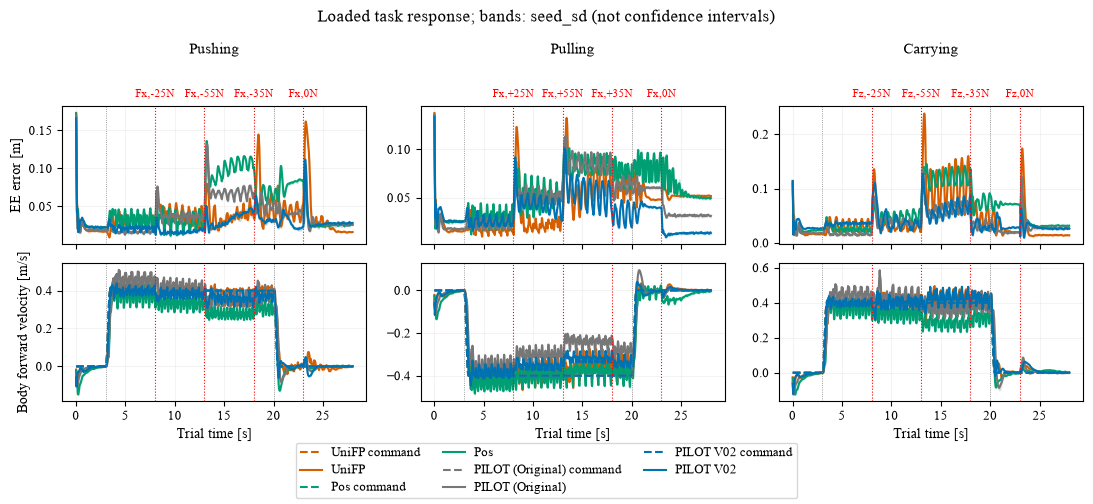

In [4]:
import exp2_analysis as engine
engine = importlib.reload(engine)
COMPARE = cohort.comparison_config(CONFIG, summaries, 2)
tables, figure, diagnostics = engine.compare(COMPARE)
for name, table in tables.items():
    print(name)
    display(table)
display(figure)
print("\n".join(diagnostics) or "Compatible protocols and coverage.")


In [5]:
for method, summary in summaries.items():
    print(summary["display_name"], "stage diagnostics")
    display(pd.DataFrame(summary["stage_aggregates"]))


UniFP stage diagnostics


,profile,loading,stage,metric,unit,mean,sd,contributing_seeds
0,pushing,loaded,stationary_unloaded,ee_error_m,m,0.023314,0.000216,3
1,pushing,loaded,stationary_unloaded,planar_velocity_error_m_s,m/s,0.028738,0.000286,3
2,pushing,loaded,stationary_unloaded,yaw_error_rad_s,rad/s,0.057995,0.000906,3
3,pushing,loaded,stationary_unloaded,S_track,fraction,0.974318,0.001218,3
4,pushing,loaded,start_ramp,ee_error_m,m,0.013971,0.000302,3
...,...,...,...,...,...,...,...,...
103,carrying,loaded,loaded_stationary,S_track,fraction,1.000000,0.000000,3
104,carrying,loaded,released,ee_error_m,m,0.025797,0.000191,3
105,carrying,loaded,released,planar_velocity_error_m_s,m/s,0.022607,0.000178,3
106,carrying,loaded,released,yaw_error_rad_s,rad/s,0.041598,0.000321,3


Pos stage diagnostics


,profile,loading,stage,metric,unit,mean,sd,contributing_seeds
0,pushing,loaded,stationary_unloaded,ee_error_m,m,0.027112,0.000216,3
1,pushing,loaded,stationary_unloaded,planar_velocity_error_m_s,m/s,0.045868,0.000239,3
2,pushing,loaded,stationary_unloaded,yaw_error_rad_s,rad/s,0.058135,0.000858,3
3,pushing,loaded,stationary_unloaded,S_track,fraction,0.980134,0.000134,3
4,pushing,loaded,start_ramp,ee_error_m,m,0.029399,0.000125,3
...,...,...,...,...,...,...,...,...
103,carrying,loaded,loaded_stationary,S_track,fraction,0.999840,0.000277,3
104,carrying,loaded,released,ee_error_m,m,0.035777,0.000289,3
105,carrying,loaded,released,planar_velocity_error_m_s,m/s,0.029325,0.000342,3
106,carrying,loaded,released,yaw_error_rad_s,rad/s,0.069653,0.000708,3


PILOT (Original) stage diagnostics


,profile,loading,stage,metric,unit,mean,sd,contributing_seeds
0,pushing,loaded,stationary_unloaded,ee_error_m,m,0.024031,0.000128,3
1,pushing,loaded,stationary_unloaded,planar_velocity_error_m_s,m/s,0.036776,0.000568,3
2,pushing,loaded,stationary_unloaded,yaw_error_rad_s,rad/s,0.057167,0.000828,3
3,pushing,loaded,stationary_unloaded,S_track,fraction,0.980089,0.000077,3
4,pushing,loaded,start_ramp,ee_error_m,m,0.023517,0.000430,3
...,...,...,...,...,...,...,...,...
103,carrying,loaded,loaded_stationary,S_track,fraction,0.995627,0.002491,3
104,carrying,loaded,released,ee_error_m,m,0.032131,0.000437,3
105,carrying,loaded,released,planar_velocity_error_m_s,m/s,0.033737,0.000483,3
106,carrying,loaded,released,yaw_error_rad_s,rad/s,0.086005,0.000886,3


PILOT V02 stage diagnostics


,profile,loading,stage,metric,unit,mean,sd,contributing_seeds
0,pushing,loaded,stationary_unloaded,ee_error_m,m,0.027261,0.000342,3
1,pushing,loaded,stationary_unloaded,planar_velocity_error_m_s,m/s,0.025968,0.000201,3
2,pushing,loaded,stationary_unloaded,yaw_error_rad_s,rad/s,0.046570,0.001123,3
3,pushing,loaded,stationary_unloaded,S_track,fraction,0.982819,0.001099,3
4,pushing,loaded,start_ramp,ee_error_m,m,0.025764,0.000305,3
...,...,...,...,...,...,...,...,...
103,carrying,loaded,loaded_stationary,S_track,fraction,1.000000,0.000000,3
104,carrying,loaded,released,ee_error_m,m,0.028540,0.000203,3
105,carrying,loaded,released,planar_velocity_error_m_s,m/s,0.026422,0.000048,3
106,carrying,loaded,released,yaw_error_rad_s,rad/s,0.043943,0.000802,3


## Confidence Intervals
Dedicated CSVs report **V02 minus comparator** in native units (tracking fractions remain fractions; physical-limit percentages remain percentages). Broad metric CIs bootstrap paired **evaluation-seed summaries**, preserving the original trial weighting, pooled limit denominators, recovery censoring, and stage definitions. They are pointwise, exploratory fixed-checkpoint intervals, not independent-training uncertainty; three seeds give limited precision. Missing metrics stay unavailable. Distribution plots remain descriptive, not additional significance tests.

In [6]:
display(confidence)
print("Dedicated CIs:", Path(CONFIG["output_dir"]) / "exp2/exp2_metric_confidence_intervals.csv")
print("Tables and figures:", COMPARE["output_dir"])


,stage,metric,unit,profile,loading,reference_method,comparator_method,reference_checkpoint,comparator_checkpoint,evaluation_seeds,...,comparator_available_seeds,confidence_level,bootstrap_resamples,resampling_unit,status,reference_mean,comparator_mean,difference,ci_low,ci_high
0,all,S_track,fraction,carrying,loaded,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.982043,0.874919,0.107124,0.105943,0.107829
1,all,S_track,fraction,carrying,loaded,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.982043,0.828257,0.153786,0.152000,0.155314
2,all,S_track,fraction,carrying,loaded,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,3,...,3,0.95,10000,paired evaluation seed,available,0.982043,0.968690,0.013352,0.012171,0.014443
3,all,S_track,fraction,pulling,loaded,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.993624,0.976967,0.016657,0.015929,0.017329
4,all,S_track,fraction,pulling,loaded,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.993624,0.955724,0.037900,0.037400,0.038643
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,stationary_unloaded,yaw_error_rad_s,rad/s,pulling,loaded,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.045913,0.058793,-0.012879,-0.013301,-0.012580
482,stationary_unloaded,yaw_error_rad_s,rad/s,pulling,loaded,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,3,...,3,0.95,10000,paired evaluation seed,available,0.045913,0.057186,-0.011273,-0.011765,-0.010399
483,stationary_unloaded,yaw_error_rad_s,rad/s,pushing,loaded,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.046570,0.057995,-0.011425,-0.011771,-0.011075
484,stationary_unloaded,yaw_error_rad_s,rad/s,pushing,loaded,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.046570,0.058135,-0.011565,-0.011959,-0.011214


Dedicated CIs: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp2/exp2_metric_confidence_intervals.csv
Tables and figures: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp2/comparison
